# Fox Kemper


In [1]:
import os
import sys
from pathlib import Path
sys.path.insert(0, str(Path("/scratch/jczhang/submeso_data_driven").resolve()))

from src.utils import make_grid
from src.utils import build_coarse_grid 
from src.utils import read_mitgcm 
import xarray as xr 
import numpy as np 
import gsw 
import importlib 
from src.utils import coarsen_UVWTS 
from MITgcmutils import mds 
importlib.reload(coarsen_UVWTS) # force reload

def buo_coarse(
    ds_grid: xr.Dataset,
    ds_ocean: xr.Dataset,
    boundary_Y: str = "fill"
) -> xr.DataArray:

    # merge the two dataset
    ds = xr.merge([ds_grid, ds_ocean])
    grid = make_grid.make_grid_periodic_x(ds)
    # water collumn
    # Etabar: sea-surface height (j,i) [m]; broadcast add → z_c(k,j,i)
    z_rel = ds["RC"] - ds["Eta"]  # RC is negative, RC - Eta gives the depth of water column
    
    # TEOS10 EOS
    # model output is salinity and potential temperature
    # gsw function need absolute salinity and conservative temperature
    lat0, lon0 = -55.0, 153.0
    lat2d = xr.full_like(ds["T"].isel(k=0), lat0)               # (j,i)
    lon2d = xr.full_like(ds["T"].isel(k=0), np.mod(lon0, 360.)) # (j,i)

    # TEOS-10 sea pressure from depth (returns dbar)
    p_dbar = xr.apply_ufunc(
        gsw.p_from_z, z_rel, lat2d,
        dask="parallelized",
        output_dtypes=[ds["T"].dtype],
    )


    # --- convert SP, θ -> SA, CT -> ρ ---
    SA  = xr.apply_ufunc(gsw.SA_from_SP, ds["S"], p_dbar, lon2d, lat2d,
                         dask='parallelized', output_dtypes=[ds["S"].dtype])
    CT  = xr.apply_ufunc(gsw.CT_from_pt, SA, ds["T"],
                         dask='parallelized', output_dtypes=[ds["T"].dtype])
    rho = xr.apply_ufunc(gsw.rho, SA, CT, p_dbar,
                         dask='parallelized', output_dtypes=[ds["T"].dtype])  # kg m^-3
    # constants
    g = 9.81 # gravity
    rho0 = 1035 # density
    # buoyancy
    b = (-g * (rho - rho0) / rho0).where(ds["hFacC"] > 0)  # m s^-2
    b.name = "buoyancy"
    b.attrs.update(units="m s^-2", long_name="buoyancy (TEOS-10)")
    
    # ---- buoyancy gradient ----
    # Face wet masks (avoid bleeding across land/blocked faces)
    wetU = ds["hFacW"] > 0
    wetV = ds["hFacS"] > 0
    dbdx_u = (grid.diff(b, "X") / ds["DXC"]).where(wetU)                   # (k,j,i_g)
    dbdy_v = (grid.diff(b, "Y", boundary=boundary_Y) / ds["DYC"]).where(wetV)  # (k,j_g,i)
    return b, dbdx_u, dbdy_v

In [2]:
def _k_name(da): # Find the vertical dim name that matches your data 
    for cand in ("k", "Z", "z", "lev", "k_c"): 
        if cand in da.dims: 
            return cand 
            # fallback: assume first dim is vertical (adjust if needed) 
    return da.dims[0]

def mld_integrals_for_MEI( dbdx_u: xr.DataArray, # (k,j,i_g) ∂b/∂x at U 
                           dbdy_v: xr.DataArray, # (k,j_g,i) ∂b/∂y at V 
                           kpphbl_C: xr.DataArray, # (j,i) ML depth at C 
                           ds_grid: xr.Dataset, 
                           grid, 
                           sigma_is_buoyancy: bool = True, 
                           g: float = 9.81, 
                           rho0: float = 1035.0, 
                         ): 
    # ---- 0) Standardize the vertical index 'k' everywhere ---- 
    RF = ds_grid["RF"] # (k_p1), negative downward , 50
    K = RF.sizes["k_p1"] - 1  # 49
    k_index = xr.DataArray(np.arange(K), dims=("k",), name="k") 
    ku = _k_name(dbdx_u) 
    kv = _k_name(dbdy_v) 
    dbdx_u = (dbdx_u.rename({ku: "k"}) .assign_coords(k=k_index) .reset_coords(drop=True)) 
    dbdy_v = (dbdy_v.rename({kv: "k"}) .assign_coords(k=k_index) .reset_coords(drop=True)) 
    # Mixed-layer depth at faces 
    H_C = kpphbl_C.clip(min=0.0) 
    H_U = grid.interp(H_C, "X", to="left") # (j,i_g) 
    H_V = grid.interp(H_C, "Y", to="left") # (j_g,i) 
    # ---- 1) Interfaces as positive-down depths with SAME 'k' coords ---- 
    ztop1d = (-RF.isel(k_p1=slice(0, -1))).rename(k_p1="k").assign_coords(k=k_index) # 0 to Nr -1
    zbot1d = (-RF.isel(k_p1=slice(1, None))).rename(k_p1="k").assign_coords(k=k_index) # 1 to Nr
    # Broadcast to faces (will use positional matching now that 'k' is unified) 
    ztop_U = ztop1d.broadcast_like(dbdx_u) # (k,j,i_g) 
    zbot_U = zbot1d.broadcast_like(dbdx_u) 
    ztop_V = ztop1d.broadcast_like(dbdy_v) # (k,j_g,i) 
    zbot_V = zbot1d.broadcast_like(dbdy_v) 
    # Partial-cell thickness on faces 
    thkU = (zbot_U - ztop_U) * ds_grid["hFacW"] 
    thkV = (zbot_V - ztop_V) * ds_grid["hFacS"] 
    # ---- 2) Overlap thickness with [0, H_face] (no xr.minimum) ---- 
    H3U = H_U.broadcast_like(dbdx_u) 
    H3V = H_V.broadcast_like(dbdy_v) 
    # min(H, zbot) = where(H <= zbot, H, zbot) 
    minHU = xr.where(H3U <= zbot_U, H3U, zbot_U) 
    minHV = xr.where(H3V <= zbot_V, H3V, zbot_V) 
    wU = xr.where(H3U > ztop_U, minHU - ztop_U, 0.0) 
    wV = xr.where(H3V > ztop_V, minHV - ztop_V, 0.0) 
    # clip and enforce partial thickness 
    wU = xr.where(wU > 0, xr.where(wU < thkU, wU, thkU), 0.0) 
    wV = xr.where(wV > 0, xr.where(wV < thkV, wV, thkV), 0.0) 
    # ---- 3) Integrals over 0..H (∑ sigma * dzLoc) ---- 
    intX = (dbdx_u.fillna(0.0) * wU).sum("k") # (j,i_g) 
    intY = (dbdy_v.fillna(0.0) * wV).sum("k") # (j_g,i) 
    # ---- 4) Convert if sigma are density-gradients (yours are buoyancy-gradients) ---- 
    if sigma_is_buoyancy: 
        dBuoyX_Hu, dBuoyY_Hv = intX, intY 
        out_units = "s^-2 m" 
    else: 
        fac = -g / rho0 
        dBuoyX_Hu, dBuoyY_Hv = fac * intX, fac * intY 
        out_units = "kg m^-4 s^-2" 
    # Optional: mask dry faces 
    wetU = (ds_grid["hFacW"] > 0).any("k") 
    wetV = (ds_grid["hFacS"] > 0).any("k") 
    dBuoyX_Hu = dBuoyX_Hu.where(wetU) 
    dBuoyY_Hv = dBuoyY_Hv.where(wetV) 
    dBuoyX_Hu.name, dBuoyY_Hv.name = "dBuoyX_Hu", "dBuoyY_Hv" 
    for da in (dBuoyX_Hu, dBuoyY_Hv): 
        da.attrs["long_name"] = "ML integral of horizontal buoyancy gradient" 
        da.attrs["units"] = out_units 
    return dBuoyX_Hu, dBuoyY_Hv

In [3]:
import numpy as np 
import xarray as xr 
def compute_Lf_MEI( dBuoyX_Hu: xr.DataArray, # (j, i_g) 
                    dBuoyY_Hv: xr.DataArray, # (j_g, i) 
                    b: xr.DataArray, # (k, j, i) buoyancy at C 
                    H_C: xr.DataArray, # (j, i) ML depth at C 
                    f_eff_C: xr.DataArray, # (j, i) 
                    ds_grid: xr.Dataset, 
                    grid, 
                    g: float = 9.81, 
                    rho0: float = 1035.0, 
                    LfMin: float = 1000.0, ): 
    # --- A) Standardize vertical coord 'k' everywhere ----------------------- 
    RF = ds_grid["RF"] # (k_p1) 
    K = RF.sizes["k_p1"] - 1 
    k_idx = xr.DataArray(np.arange(K), dims=("k",), name="k") 
    def to_k(da): 
        # rename vertical dim to 'k' if needed, then assign common index 
        for cand in ("k", "Z", "z", "lev", "k_c"): 
            if cand in da.dims: 
                if cand != "k": 
                    da = da.rename({cand: "k"}) 
                break 
        if "k" in da.dims: 
                da = da.assign_coords(k=k_idx).reset_coords(drop=True) 
        return da 
    b = to_k(b) 
    hFacC = to_k(ds_grid["hFacC"]) # (k,j,i) with unified k 
    # (dBuoyX_Hu, dBuoyY_Hv, H_C, f_eff_C are 2D—no k to fix) 
    # interfaces as positive-down depths with SAME 'k' coords 
    ztop1d = (-RF.isel(k_p1=slice(0, -1))).rename(k_p1="k").assign_coords(k=k_idx) 
    zbot1d = (-RF.isel(k_p1=slice(1, None))).rename(k_p1="k").assign_coords(k=k_idx) 
    ztop = ztop1d.broadcast_like(b) 
    zbot = zbot1d.broadcast_like(b) 
    # --- 1) MsqH at centers from face integrals averaged to C --------------- 
    dBx_C = grid.interp(dBuoyX_Hu, 'X') # U->C 
    dBy_C = grid.interp(dBuoyY_Hv, 'Y') # V->C 
    MsqH = np.sqrt(0.25*(dBx_C**2 + dBy_C**2)) # s^-2 m 
    # --- 2) NHmixLay at C via ML overlap (honor partial cells) -------------- 
    thkC = (zbot - ztop) * hFacC # partial thickness 
    H3C = H_C.assign_coords().broadcast_like(b) # (k,j,i) with unified k 
    # min(H,zbot) without xr.minimum (avoids version issues) 
    minHC = xr.where(H3C <= zbot, H3C, zbot) 
    wC = xr.where(H3C > ztop, minHC - ztop, 0.0) 
    wC = xr.where(wC > 0, xr.where(wC < thkC, wC, thkC), 0.0) 
    # ∂b/∂z at C using interface spacing (downward-positive dz) 
    db = b - b.shift(k=1) 
    dz = (ztop - ztop.shift(k=1)) 
    sigmaR = (db / dz).where(dz.notnull()) 
    sigmaR_pos = xr.where(sigmaR < 0.0, -sigmaR, 0.0) 
    NH_term = (sigmaR_pos * wC).sum("k") # units: s^-2 * m 
    NHmixLay = np.sqrt(NH_term * H_C.clip(min=0.0)).fillna(0.0) 
    # --- 3) Lf at centers --------------------------------------------------- 
    fC = xr.where(f_eff_C > 0, f_eff_C, np.nan) 
    cand1 = MsqH / (fC**2) # m 
    cand2 = NHmixLay / fC # m 
    Lf_center = xr.ufuncs.maximum( xr.ufuncs.maximum(cand1.fillna(0.0), cand2.fillna(0.0)), LfMin ).rename("Lf") 
    Lf_center.attrs.update(long_name="MEI length scale at centers", units="m") 
    # --- 4) centers -> faces for streamfunction denominators ---------------- 
    Lf_U = grid.interp(Lf_center, 'X', to='left') # C->U 
    Lf_V = grid.interp(Lf_center, 'Y', to='left') # C->V 
    Lf_U.name, Lf_V.name = "Lf_U", "Lf_V" 
    return Lf_center, Lf_U, Lf_V

In [4]:
# modules 
from src.utils import read_mitgcm 
from src.utils import coarsen_UVWTS 
from src.utils import build_coarse_grid 
from src.utils import make_grid
import numpy as np 
import xarray as xr 
from MITgcmutils import mds 
from src.utils import mld_avg

# ---------------------------- parameters -------------------------------------
t = 18458496

box_i = box_j = 10 
# ---------------------------- MITgcm Path ------------------------------------- 
path_scratch = '/scratch/jczhang/' 
path_MITgcm = 'MITgcm_baroclinic_instability_old/MITgcm/verification/tutorial_reentrant_channel/run/'
grid_dir = path_scratch + path_MITgcm 
# ---------------------------- grid ------------------------------------- 
ds_fine = read_mitgcm.read_mitgrid_staggered(grid_dir) 
ds_coarse = build_coarse_grid.build_coarse_grid_staggered(ds_fine,box_j=box_j, box_i=box_i) 
grid = make_grid.make_grid_periodic_x(ds_coarse) 
# ---------------------------- Ce, ds ------------------------------------- 
# efficiency coefficient Ce 
C_e = 1.011
# hard upper cap - useless for my case, since dx < 111 km 
submeso_Lmax = 10000 # m 
# delta_s: local coarse model gridscale dimension 
delta_sx = ds_coarse["DXC"].clip(max=submeso_Lmax) # (j, i_g) 
delta_sy = ds_coarse["DYC"].clip(max=submeso_Lmax) # (j_g, i) 
# 
index = 20105136
# ---------------------------- mixed layer depth ------------------------------------ 
# mixed layer depth 
kpphbl = xr.open_dataset("../../../../data_5km/save_coarse/13901616_nc/kpphbl_12hmean_coarse.nc", engine="h5netcdf")
kpphbl = kpphbl["kpphbl"].sel(time=index)
H_U = grid.interp(kpphbl, 'X', to='left') # (j, i_g) 
H_V = grid.interp(kpphbl, 'Y', to='left') # (j_g, i) 
# ---------------------------- buoyancy ---------------------------------------------
T = xr.open_dataset("../../../../data_5km/save_coarse/13901616_nc/T_12hmean_coarse.nc", engine="h5netcdf")
T = T["T"].sel(time=index)
S = xr.open_dataset("../../../../data_5km/save_coarse/13901616_nc/S_12hmean_coarse.nc", engine="h5netcdf")
S = S["S"].sel(time=index)
Eta = xr.open_dataset("../../../../data_5km/save_coarse/13901616_nc/Eta_12hmean_coarse.nc", engine="h5netcdf")
Eta = Eta["Eta"].sel(time=index)
#  combine all the variables
ds_ocean_c = xr.Dataset(dict(T=T, S=S, Eta=Eta)) 
# calculate the buoyancy 
b, dBdx_u, dBdy_V = buo_coarse(ds_coarse, ds_ocean_c, "fill") 
# integral over mixed layer 
dBuoyX_Hu, dBuoyY_Hv = mld_integrals_for_MEI( dBdx_u, dBdy_V, kpphbl, ds_coarse, grid, sigma_is_buoyancy=True ) 
# ---------------------------- coriolis and tau------------------------------------- 
f0 = -1.363e-4 # s^-1 
beta = 1.313e-11 # s^-1 m^-1 
subMeso_invTau = 1.6e-6 
YC_da = xr.DataArray(ds_coarse["YC"], dims=('j','i')) 
y_ref = float(YC_da.mean()) 
f = (f0 + beta*(YC_da - y_ref)) # (j,i), s^-1 
f_eff = np.hypot(f, subMeso_invTau) 
f_U = grid.interp(f_eff, 'X', to='left') # (j,i_g) 
f_V = grid.interp(f_eff, 'Y', to='left') # (j_g,i) 
# ---------------------------- Lf = max(M/f, NH/|f|, Lf_min)------------------------------------- 
Lf_center, Lf_U, Lf_V = compute_Lf_MEI(dBuoyX_Hu=dBuoyX_Hu, dBuoyY_Hv=dBuoyY_Hv, b=b, H_C=kpphbl.clip(min=0.0), f_eff_C=f_eff, ds_grid=ds_coarse, grid=grid, LfMin=3600.0 ) 
# ---------------------------- mu(z)------------------------------------- 
# RF is negative downward (k_p1 interfaces); use it directly. 
rF = ds_coarse["RF"].rename(k_p1="k") # (k) ≤ 0 
rF_U = rF.broadcast_like(dBdx_u) # (k,j,i_g) 
rF_V = rF.broadcast_like(dBdy_V) # (k,j_g,i) 
# Mixed-layer depths on faces (positive) 
H_U = grid.interp(kpphbl.clip(min=0.0), 'X', to='left') 
H_V = grid.interp(kpphbl.clip(min=0.0), 'Y', to='left') 
# z2H must be negative inside the ML: [-2, 0] 
z2H_U = xr.where(H_U > 0, 2.0 * rF_U / H_U.broadcast_like(dBdx_u), 0.0) 
z2H_V = xr.where(H_V > 0, 2.0 * rF_V / H_V.broadcast_like(dBdy_V), 0.0) 
def mu_from(z2H): 
    q = (1.0 + z2H)**2 
    mu = (1.0 - q) * (1.0 + (5.0/21.0)*q) 
    return xr.where(mu > 0.0, mu, 0.0) 
muU = mu_from(z2H_U) # (k,j,i_g) 
muV = mu_from(z2H_V) # (k,j_g,i) 
# --- gridscale caps at faces (MIN(dx, Lmax), MIN(dy, Lmax)) --- 
dx_cap_U = ds_coarse["DXC"].clip(max=submeso_Lmax) # already (j, i_g) 
dy_cap_V = ds_coarse["DYC"].clip(max=submeso_Lmax) # already (j_g, i) 
# --- 2D streamfunction amplitudes at faces (depth-integrated) --- 
# bring the "other" horizontal component to the target face
dBuoyY_on_U = grid.interp(dBuoyY_Hv, 'Y')          # j_g,i -> j,i
dBuoyY_on_U = grid.interp(dBuoyY_on_U, 'X', to='left')

dBuoyX_on_V = grid.interp(dBuoyX_Hu, 'X')          # j,i_g -> j,i
dBuoyX_on_V = grid.interp(dBuoyX_on_V, 'Y', to='left')

PsiU0 = ( C_e * dBuoyY_on_U * H_U * dx_cap_U / (Lf_U * f_U) ).fillna(0.0)
PsiV0 = (-C_e * dBuoyX_on_V * H_V * dy_cap_V / (Lf_V * f_V) ).fillna(0.0)
# --- 3D streamfunctions using mu(z/H) --- 
muU_ = muU.transpose('k','j','i_g') # ensure consistent order for broadcasting 
muV_ = muV.transpose('k','j_g','i') 
PsiX = PsiU0.broadcast_like(muU_) * muU_ # (k,j,i_g) 
PsiY = PsiV0.broadcast_like(muV_) * muV_ # (k,j_g,i) 
PsiX.name, PsiY.name = "GM_PsiX_MEI", "GM_PsiY_MEI"

# --- grads of mean T on C, then to W (k,j,i) ---
wetU = ds_coarse["hFacW"] > 0
wetV = ds_coarse["hFacS"] > 0

dTdx_U = (grid.diff(T, 'X') / ds_coarse["DXC"]).where(wetU)      # (k,j,i_g)
dTdy_V = (grid.diff(T, 'Y', boundary='fill') / ds_coarse["DYC"]).where(wetV)  # (k,j_g,i)

# bring face-grads to centers
dTdx_C = grid.interp(dTdx_U.fillna(0.0), 'X')    # (k,j,i)
dTdy_C = grid.interp(dTdy_V.fillna(0.0), 'Y')    # (k,j,i)
# average C→W so vertical index matches Ψ(k,·,·) at W levels
dTdx_W = 0.5*(dTdx_C + dTdx_C.shift(k=1))
dTdy_W = 0.5*(dTdy_C + dTdy_C.shift(k=1))

# --- bring Ψ components to centers (same W levels) ---
PsiX_C = grid.interp(PsiX, 'X')    # (k,j,i)
PsiY_C = grid.interp(PsiY, 'Y')    # (k,j,i)

# --- vertical eddy temp flux from cross product ----------------------------
Fz_T_cross = (PsiX_C * dTdy_W - PsiY_C * dTdx_W).rename("Fz_T_cross")   # (k,j,i)
Fz_T_cross.attrs.update(long_name="(Ψ × ∇T)_z", units="K m s^-1?  see note")

# (optional) convert to heat units
rho0, cp = 1035.0, 3990.0
Qz_T_cross = (rho0 * cp) * Fz_T_cross

Qz_T_cross.name = "Qz_T_cross"
Qz_T_cross.attrs.update(units="W m^-2")
submeso_wT_FK = mld_avg.mld_avg(Qz_T_cross, kpphbl, ds_coarse)
# 
dbdx_C = grid.interp(dBdx_u.fillna(0.0), 'X')
dbdy_C = grid.interp(dBdy_V.fillna(0.0), 'Y')

dbdx_W = 0.5 * (dbdx_C + dbdx_C.shift(k=1))
dbdy_W = 0.5 * (dbdy_C + dbdy_C.shift(k=1))

Fz_b = (PsiX_C * dbdy_W - PsiY_C * dbdx_W).rename("Fz_b")
Fz_b_ml = mld_avg.mld_avg(Fz_b, kpphbl, ds_coarse)

BlockingIOError: [Errno 11] Unable to synchronously open file (unable to lock file, errno = 11, error message = 'Resource temporarily unavailable')

In [ ]:
import sys
from pathlib import Path
sys.path.append(str(Path.cwd().parent))
from src.utils import coarsen_UVWTS
from src.utils import read_mitgcm
from src.utils import build_coarse_grid
import numpy as np
from matplotlib import pyplot as plt
import cmocean.cm as cmo
from matplotlib.colors import TwoSlopeNorm
from matplotlib.colors import Normalize
from src.utils import wT
import xarray as xr
from MITgcmutils import mds
from src.utils import mld_avg
import importlib
importlib.reload(wT)   # force reload
importlib.reload(read_mitgcm) 
importlib.reload(build_coarse_grid) 
#  MITgcm path
# ---------------------------- MITgcm Path ------------------------------------- 
path_scratch = '/scratch/jczhang/' 
path_MITgcm = 'MITgcm_baroclinic_instability_old/MITgcm/verification/tutorial_reentrant_channel/run/'
grid_dir = path_scratch + path_MITgcm
# choose a vertical level
box_i, box_j=10, 10
# get the grid variables and create the ds
ds_fine = read_mitgcm.read_mitgrid_staggered(grid_dir)
ds_coarse = build_coarse_grid.build_coarse_grid_staggered(ds_fine,box_j=box_j, box_i=box_i)

# coordinate variable
XC = ds_fine["XC"].values
YC = ds_fine["YC"].values
XCc = ds_coarse["XC"].values
YCc = ds_coarse["YC"].values

# get the truth 
index = 20105136
data = np.load("../../../data/mld/wT.npz")
time_index = data["time_index"]
wT_sub = data["data"]
idx = np.where(time_index == index)[0]
wT_sub = wT_sub[idx[0]]
# get the FK heat flux 
submeso_wT_FK = submeso_wT_FK[62:118, 2:58]

Text(0.5, 0.98, 'submesoscale heat flux (t=[ 5500080  5501808  5503536 ... 21143664 21145392 21147120]) — fine vs coarse')

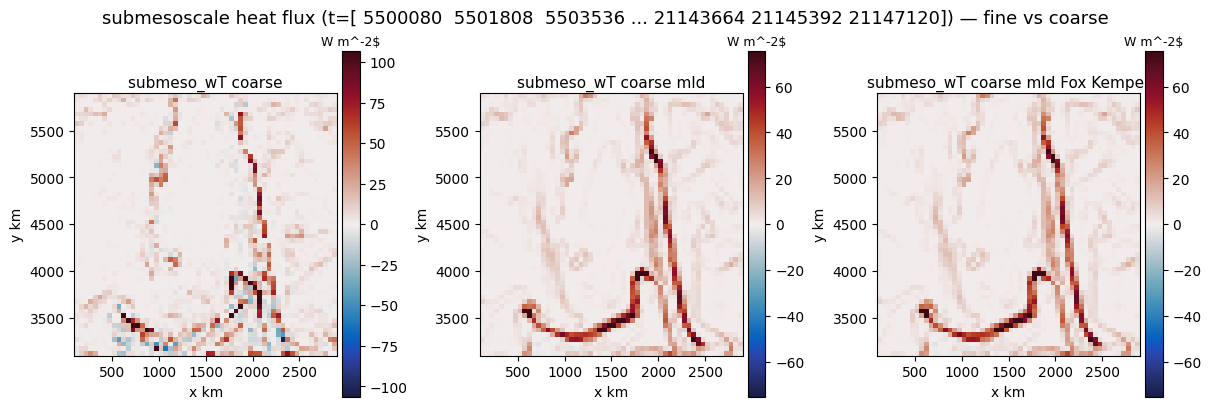

In [58]:
# limits function
def sym_limits(Z, q = 0.995):
    v = np.nanquantile(np.abs(Z), q)
    return float(v)

def pos_limits(Z, q=0.995):
    v = np.nanquantile(Z, q)
    return float(v)

# div_coarse_mld[2403 + _ ,:,:]
fields = {
    # "submesoscale wT":  {"Z": strain_fine[k,:,:],    "units": r"m s$^{-1}$",    "kind": "signed", "cmap": cmo.balance, "X": XC/1e3, "Y": YC/1e3 },
    "submeso_wT coarse":  {"Z": wT_sub,    "units": r"W m^-2$",    "kind": "signed", "cmap": cmo.balance, "X": XCc[62:118,2:58]/1e3, "Y": YCc[62:118,2:58]/1e3},
    "submeso_wT coarse mld":  {"Z": submeso_wT_FK,  "units": r"W m^-2$", "kind": "signed", "cmap": cmo.balance, "X": XCc[62:118,2:58]/1e3, "Y": YCc[62:118,2:58]/1e3},
    "submeso_wT coarse mld Fox Kemper":  {"Z": submeso_wT_FK,  "units": r"W m^-2$", "kind": "signed", "cmap": cmo.balance, "X": XCc[62:118,2:58]/1e3, "Y": YCc[62:118,2:58]/1e3},
}

# Compute norms/limits per field
for key, meta in fields.items():    # key is the variable name, meta is the dict contains the variables, units...
    Z = meta["Z"]
    if meta["kind"] == "signed":
        q = sym_limits(Z)
        meta["norm"] = TwoSlopeNorm(vcenter=0.0, vmin=-q, vmax=+q)
    elif meta["kind"] == "positive":
        q = pos_limits(Z)
        meta["norm"] = Normalize(vmin=0.0, vmax=q)
    elif meta["kind"] == "seq":
        meta["norm"] = Normalize(vmin=np.nanmin(Z), vmax=np.nanmax(Z))
    else:
        meta["norm"] = None

# Plot: 2×5
fig, axes = plt.subplots(1, 3, figsize=(12, 4), constrained_layout=True, squeeze=False)
axes = axes.ravel()

for ax, (title, meta) in zip(axes, fields.items()):
    X = meta["X"]; Y = meta["Y"]; Z = meta["Z"]; 
    cmap = meta["cmap"]
    norm = meta["norm"]
    pc = ax.pcolormesh(X, Y, Z, shading='auto', cmap=cmap, norm=norm)
    ax.set_aspect('equal', adjustable='box')
    ax.set_title(title, fontsize=11, pad=4)
    ax.set_xlabel('x km'); ax.set_ylabel('y km')
    cb = fig.colorbar(pc, ax=ax, pad=0.02)
    cb.ax.set_title(meta["units"], pad=4, fontsize=9)

fig.suptitle(f"submesoscale heat flux (t={time_index}) — fine vs coarse", fontsize=13)


<module 'src.utils.wT' from '/scratch/jczhang/submeso_data_driven/src/utils/wT.py'>


# Save data

In [2]:
import os
import sys
from pathlib import Path
sys.path.insert(0, str(Path("/scratch/jczhang/submeso_data_driven").resolve()))

import numpy as np
import xarray as xr
import h5netcdf

os.environ["HDF5_USE_FILE_LOCKING"] = "FALSE"

from src.utils import read_mitgcm


def make_mitgcm_loader_onevar(grid_dir, read_mitgcm, var: str, dims):
    """
    Returns load_snapshot(it) -> xr.DataArray for ONE variable.
    """
    def load_snapshot(it: int) -> xr.DataArray:
        da = read_mitgcm._ocean_var(grid_dir, var, it, dims)
        da = da.drop_vars("time", errors="ignore")
        da.name = var
        return da
    return load_snapshot


def _12h_mean_to_netcdf_onevar(
    start_time_index: int,
    end_time_index: int,
    load_snapshot,                   # fn(it:int) -> xr.DataArray
    out_nc: str,                     # e.g. "./out_nc/T_12hmean.nc"
    varname: str,                    # e.g. "T"
    block_size: int = 12,
    step: int = 18,                  # hourly output for deltaT=200 s
    time_name: str = "time",
    dtype=np.float32,
    skip_missing: bool = False,
    print_every: int = 20,
):
    start_time_index = int(start_time_index)
    end_time_index   = int(end_time_index)
    step             = int(step)

    if end_time_index < start_time_index:
        raise ValueError("end_time_index must be >= start_time_index")

    out_dir = os.path.dirname(out_nc) or "."
    os.makedirs(out_dir, exist_ok=True)

    block_span = block_size * step

    # ---- read existing file info
    saved = set()
    origin_iter = start_time_index

    if os.path.exists(out_nc):
        with h5netcdf.File(out_nc, "r") as nc:
            if time_name in nc.variables:
                saved = set(map(int, nc.variables[time_name][:].tolist()))
            if "origin_iter" in nc.attrs:
                origin_iter = int(nc.attrs["origin_iter"])

            if "varname" in nc.attrs and str(nc.attrs["varname"]) != str(varname):
                raise ValueError(
                    f"{out_nc} already stores varname={nc.attrs['varname']} but you requested {varname}"
                )

    # last hour of block must be <= end_time_index
    max_n = int(np.floor((end_time_index - origin_iter - (block_size - 1) * step) / block_span))
    if max_n < 0:
        print("Not enough hourly data to form even one full 12-hour block yet.")
        return

    # ---- init file (NO coarse, save full resolution)
    def _init_file(mean_da: xr.DataArray):
        spatial_dims = tuple(mean_da.dims)
        spatial_sizes = {d: int(mean_da.sizes[d]) for d in spatial_dims}

        with h5netcdf.File(out_nc, "w") as nc:
            # dimensions
            nc.dimensions[time_name] = None
            for d, n in spatial_sizes.items():
                nc.dimensions[d] = n

            # attrs
            nc.attrs["origin_iter"] = int(origin_iter)
            nc.attrs["hourly_step"] = int(step)
            nc.attrs["block_size"] = int(block_size)
            nc.attrs["time_is_block_start"] = 1
            nc.attrs["varname"] = str(varname)

            # time coord
            tvar = nc.create_variable(
                time_name,
                dimensions=(time_name,),
                dtype="i8",
                chunks=(1,),
                maxshape=(None,),
            )
            tvar.attrs["long_name"] = "start index of each 12-hour averaging block"
            tvar.attrs["units"] = "model_iteration_index"

            # save 1D coords if available
            for d in spatial_dims:
                if d in mean_da.coords:
                    coord_vals = np.asarray(mean_da.coords[d].values)
                    cvar = nc.create_variable(
                        d,
                        dimensions=(d,),
                        dtype=coord_vals.dtype,
                    )
                    cvar[:] = coord_vals

            # data var: (time, spatial...)
            dims = (time_name,) + spatial_dims
            chunks = (1,) + tuple(spatial_sizes[d] for d in spatial_dims)
            maxshape = (None,) + tuple(spatial_sizes[d] for d in spatial_dims)

            v = nc.create_variable(
                varname,
                dimensions=dims,
                dtype="f4",
                chunks=chunks,
                maxshape=maxshape,
            )
            v.attrs["long_name"] = f"{varname} 12-hour mean"

    appended = 0
    skipped_saved = 0
    skipped_missing = 0

    nc_app = None
    try:
        for n in range(max_n + 1):
            s = origin_iter + n * block_span

            if print_every and (n % print_every == 0):
                print(f"[try] n={n}/{max_n}  block_start={s}", flush=True)

            if s in saved:
                skipped_saved += 1
                continue

            block_iters = [s + m * step for m in range(block_size)]

            snap0 = None
            sum_arr = None

            try:
                for it in block_iters:
                    print(f"  reading it={it}", flush=True)
                    da = load_snapshot(int(it))

                    if snap0 is None:
                        snap0 = da
                        sum_arr = da.values.astype(dtype, copy=True)
                    else:
                        sum_arr += da.values.astype(dtype, copy=False)

            except Exception as e:
                if skip_missing:
                    skipped_missing += 1
                    print(f"  -> missing/unreadable snapshot in block_start={s}, skip ({e})", flush=True)
                    continue
                raise

            mean_arr = sum_arr / block_size

            mean_da = snap0.copy(data=mean_arr)
            mean_da = mean_da.astype("float32")
            mean_da.name = varname

            # ---- initialize file once we know shape
            if not os.path.exists(out_nc):
                _init_file(mean_da)

            # ---- open once for appending
            if nc_app is None:
                nc_app = h5netcdf.File(out_nc, "a")

            tvar = nc_app.variables[time_name]
            write_idx = int(tvar.shape[0])

            v = nc_app.variables[varname]
            spatial_shape = v.shape[1:]
            v._h5ds.resize((write_idx + 1,) + spatial_shape)
            v[write_idx, ...] = mean_da.values.astype(np.float32, copy=False)

            tvar._h5ds.resize((write_idx + 1,))
            tvar[write_idx] = s

            saved.add(s)
            appended += 1

    finally:
        if nc_app is not None:
            nc_app.close()

    print(
        f"\nUpdated NetCDF (one var, no coarse): {out_nc}\n"
        f"  var: {varname}\n"
        f"  appended: {appended}\n"
        f"  skipped (already saved): {skipped_saved}\n"
        f"  skipped (missing hours): {skipped_missing}\n"
        f"  origin_iter={origin_iter}, step={step}, block_size={block_size}",
        flush=True,
    )


# -------------------------
# Example usage
# -------------------------
if __name__ == "__main__":
    path_scratch = "/scratch/jczhang/"
    path_MITgcm = "MITgcm_50km_FK/verification/tutorial_reentrant_channel/run"
    grid_dir = path_scratch + path_MITgcm

    dims_map = {
        "U": ("k", "j", "i_g"),
        "V": ("k", "j_g", "i"),
        "W": ("k_l", "j", "i"),
        "T": ("k", "j", "i"),
        "S": ("k", "j", "i"),
        "kpphbl": ("j", "i"),
        "Eta": ("j", "i"),
    }

    start_time_index, end_time_index, step = 2021760, 2177100, 18
    varname = "T"   # change to "W", "kpphbl", etc.

    load_var = make_mitgcm_loader_onevar(
        grid_dir,
        read_mitgcm,
        var=varname,
        dims=dims_map[varname]
    )

    out_nc = f"./{varname}_12hmean.nc"

    _12h_mean_to_netcdf_onevar(
        start_time_index=start_time_index,
        end_time_index=end_time_index,
        load_snapshot=load_var,
        out_nc=out_nc,
        varname=varname,
        block_size=12,
        step=step,
        time_name="time",
        skip_missing=False,
        print_every=20,
    )

[try] n=0/718  block_start=2021760
  reading it=2021760
  reading it=2021778
  reading it=2021796
  reading it=2021814
  reading it=2021832
  reading it=2021850
  reading it=2021868
  reading it=2021886
  reading it=2021904
  reading it=2021922
  reading it=2021940
  reading it=2021958
  reading it=2021976
  reading it=2021994
  reading it=2022012
  reading it=2022030
  reading it=2022048
  reading it=2022066
  reading it=2022084
  reading it=2022102
  reading it=2022120
  reading it=2022138
  reading it=2022156
  reading it=2022174
  reading it=2022192
  reading it=2022210
  reading it=2022228
  reading it=2022246
  reading it=2022264
  reading it=2022282
  reading it=2022300
  reading it=2022318
  reading it=2022336
  reading it=2022354
  reading it=2022372
  reading it=2022390
  reading it=2022408
  reading it=2022426
  reading it=2022444
  reading it=2022462
  reading it=2022480
  reading it=2022498
  reading it=2022516
  reading it=2022534
  reading it=2022552
  reading it=2022570

# Calculate annual, seasonal, and monthly mean of T, KPPHBL and Heat Flux

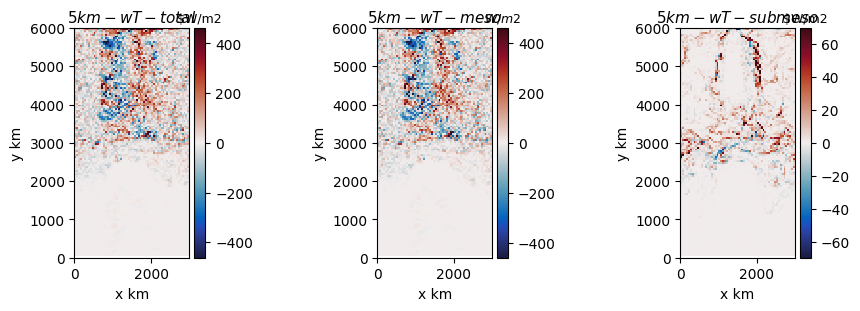

In [13]:
import sys
from pathlib import Path
sys.path.insert(0, str(Path("/scratch/jczhang/submeso_data_driven").resolve()))
import numpy as np
import xarray as xr
import matplotlib.pyplot as plt
from MITgcmutils import mds
from src.utils import coarsen_UVWTS
from src.utils import wT_submeso
from src.utils import read_mitgcm
from src.utils import coarsen_UVWTS
from src.utils import build_coarse_grid
from src.utils import mld_avg
import cmocean.cm as cmo
from matplotlib.colors import TwoSlopeNorm
from matplotlib.colors import Normalize
path_scratch = '/scratch/jczhang/'
path_high = 'MITgcm_baroclinic_instability_old/MITgcm/verification/tutorial_reentrant_channel/run/'
grid_dir = path_scratch + path_high
ds_fine = read_mitgcm.read_mitgrid_staggered(grid_dir)
ds_coarse = build_coarse_grid.build_coarse_grid_staggered(ds_fine,box_j=10, box_i=10)
# calculate the heat flux at a single time point
t = 17991936
box_i, box_j = 10, 10
W = read_mitgcm._ocean_var(grid_dir, "W", t, ("k_l","j","i"))
W_coarse = coarsen_UVWTS.coarse_field("W", W, ds_fine, box_j, box_i)
T = read_mitgcm._ocean_var(grid_dir, "T", t, ("k","j","i"))
T_coarse = coarsen_UVWTS.coarse_field("T", T, ds_fine, box_j, box_i)
ds_ocean = xr.Dataset(dict(W=W, T=T))
ds_ocean_c = xr.Dataset(dict(W=W_coarse, T=T_coarse))
wT_sub_kC, wT_bar_kC, wT_meso_kC = wT_submeso.submeso_vertical_heat_flux(ds_fine, 
                                                                         ds_coarse, 
                                                                         ds_ocean, 
                                                                         ds_ocean_c,
                                                                         box_j = box_j, box_i = box_i,
                                                                         boundary_Z = "fill", to_wm2 = True)
# mixed layer average
diagMXL = mds.rdmds(path_scratch + path_high + 'Diags/' +'DiagMXL_2d', t)
kpphbl = xr.DataArray(diagMXL[1, :,:], dims = ("j","i"), name = "kpphbl")
kpphbl_coarse = coarsen_UVWTS.coarse_field("kpphbl", kpphbl, ds_fine, box_j, box_i)
# c
wT_sub_mld = mld_avg.mld_avg(wT_sub_kC, kpphbl_coarse, ds_coarse)
wT_bar_mld = mld_avg.mld_avg(wT_bar_kC, kpphbl_coarse, ds_coarse)
wT_meso_mld = mld_avg.mld_avg(wT_meso_kC, kpphbl_coarse, ds_coarse)



def sym_limits(Z, q = 0.995):
    v = np.nanquantile(np.abs(Z), q)
    return float(v)

def pos_limits(Z, q=0.995):
    v = np.nanquantile(Z, q)
    return float(v)

def range_limits(Z, q = 0.995):
    """Return (vmin, vmax) from lower/upper quantiles."""
    vmin = np.nanquantile(Z, 1 - q)   # e.g. 0.5% if q=0.995
    vmax = np.nanquantile(Z, q)       # e.g. 99.5%
    return float(vmin), float(vmax)

# plot 
XC = ds_coarse["XC"]
YC = ds_coarse["YC"]
k = 12
fields = {
    r"$5km-wT-total$":         {"Z": wT_bar_mld[:,:],  "units": r"$W/m2",  "kind": "signed", "cmap": cmo.balance, "XC": XC/1e3, "YC":YC/1e3},
    r"$5km-wT-meso$":         {"Z": wT_meso_mld[:,:],  "units": r"$W/m2$",  "kind": "signed", "cmap": cmo.balance, "XC": XC/1e3, "YC":YC/1e3},
    r"$5km-wT-submeso$":         {"Z": wT_sub_mld[:,:],  "units": r"$W/m2",  "kind": "signed", "cmap": cmo.balance, "XC": XC/1e3, "YC":YC/1e3},
}     


# Compute norms/limits per field
for key, meta in fields.items():   
    Z = meta["Z"]
    if meta["kind"] == "signed":
        q = sym_limits(Z)
        meta["norm"] = TwoSlopeNorm(vcenter=0.0, vmin=-q, vmax=+q)
    elif meta["kind"] == "positive":
        vmin, vmax = range_limits(Z)
        meta["norm"] = Normalize(vmin=vmin, vmax=vmax)
    elif meta["kind"] == "seq":
        meta["norm"] = Normalize(vmin=np.nanmin(Z), vmax=np.nanmax(Z))
    else:
        meta["norm"] = None
# vmin, vmax = range_limits(wT_annual_low_FK[k,60:116,:], q=1)  # <-- your function
# shared_norm = Normalize(vmin=vmin, vmax=vmax)

# Plot: 2×5
fig, axes = plt.subplots(1,3, figsize=(9, 3), constrained_layout=True)
# --- dynamic number of panels ---
n_fields = len(fields)
# if only one panel
if n_fields == 1:
    axes = np.array([axes])
axes = axes.ravel()

for ax, (title, meta) in zip(axes, fields.items()):
    Z = meta["Z"]
    cmap = meta["cmap"]
    norm = meta["norm"]
    # norm = shared_norm
    XX = meta["XC"]
    YY = meta["YC"]
    pc = ax.pcolormesh(XX, YY, Z, shading='auto', cmap=cmap, norm=norm)
    ax.set_aspect('equal', adjustable='box')
    ax.set_title(title, fontsize=11, pad=4)
    ax.set_xlabel('x km'); ax.set_ylabel('y km')
    cb = fig.colorbar(pc, ax=ax, pad=0.02)
    cb.ax.set_title(meta["units"], pad=4, fontsize=9)
fig.savefig("./heatflux_5km.png")
plt.show()

In [4]:
print(wT_sub_kC)

<xarray.DataArray 'wT_sub_kC' (k: 49, j: 120, i: 60)> Size: 3MB
array([[[            nan,             nan,             nan, ...,
                     nan,             nan,             nan],
        [-6.26148191e-03, -2.88535859e-02,  9.48171233e-03, ...,
         -5.37535545e-02, -5.88333162e-02, -1.98714888e-02],
        [ 5.93518007e-03,  2.40817839e-03,  7.21578077e-03, ...,
          5.70205936e-03,  1.03945253e-02, -6.12419943e-04],
        ...,
        [-1.05294876e-01,  1.32981646e-02,  8.04152306e-02, ...,
          6.71150143e-03, -3.68282542e-03, -7.01843888e-02],
        [ 2.15951275e-01, -1.17973636e-01,  7.16286506e-02, ...,
          3.03810110e+00,  9.64607692e-01,  5.25852483e-01],
        [-3.78374745e-01, -5.35227774e-02, -2.49518575e-01, ...,
          3.45525132e-01,  4.46927057e-01, -2.11126944e-01]],

       [[            nan,             nan,             nan, ...,
                     nan,             nan,             nan],
        [-1.12494611e-02, -8.30932324e-

In [5]:
import sys
from pathlib import Path
sys.path.insert(0, str(Path("/scratch/jczhang/submeso_data_driven").resolve()))
import numpy as np
import xarray as xr
from MITgcmutils import mds
from src.utils import read_mitgcm
from src.utils import coarsen_UVWTS
path_scratch = '/scratch/jczhang/'
path_low = 'MITgcm_50km_withoutGM/verification/tutorial_reentrant_channel/run/'

# ds_fine = read_mitgcm.read_mitgrid_staggered(path_scratch + path_low)

start_iter = 2332800
delta_iter = 432
iters = np.arange(start_iter, start_iter + 360*delta_iter, delta_iter)

W_list = []

for it in iters:
    W = read_mitgcm._ocean_var(path_scratch + path_low, "W", it, ("k_l","j","i"))
    W_list.append(W)

# Stack into time series: (time, j, i)
W_all = xr.concat(W_list, dim="time").assign_coords(time=("time", iters))
# SAVE the full daily time series too
out_nc_all = "W_daily_low_noGM.nc"
W_all.name = "W"
W_all.to_netcdf(out_nc_all, engine="h5netcdf")
print("saved:", out_nc_all, "shape:", W_all.shape)
# Assign iteration index as coordinate
W_all = W_all.assign_coords(time=("time", iters))

# Now compute annual mean
W_annual = W_all.mean(dim="time")

out_nc = "W_annual_low_noGM.nc"
W_annual.name = "W"  # give it a variable name inside the file
W_annual.to_netcdf(out_nc, engine="h5netcdf")
print("saved:", out_nc)

saved: W_daily_low_noGM.nc shape: (360, 49, 120, 60)
saved: W_annual_low_noGM.nc


In [41]:
ds_T_FK = xr.open_dataset("./W_annual_low_FK.nc", engine="h5netcdf")
print(ds_T_FK)

<xarray.Dataset> Size: 3MB
Dimensions:  (k_l: 49, j: 120, i: 60)
Dimensions without coordinates: k_l, j, i
Data variables:
    W        (k_l, j, i) float64 3MB ...


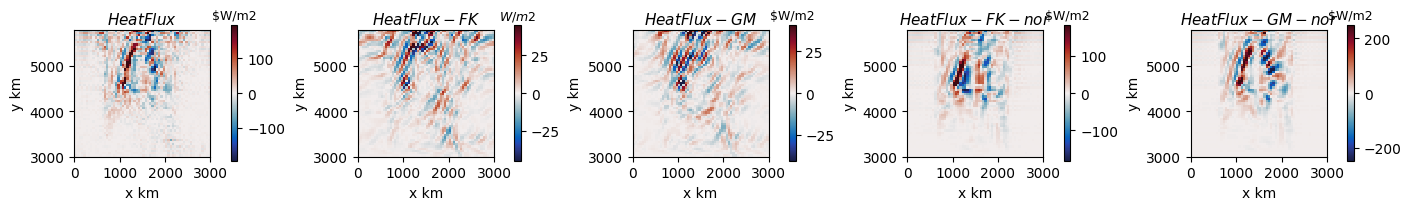

In [5]:
# High-resolution submesoscale heat flux
# ML_predicted submesoscale heat flux
# low-resolution submesoscale heat flux
# low resolution submesoscale heat flux with Fox Kemper parameterization

# path issue
import sys
from pathlib import Path
sys.path.insert(0, str(Path("/scratch/jczhang/submeso_data_driven").resolve()))

# check the velocity field and vorticity field
import numpy as np
import xarray as xr
from src.utils import read_mitgcm
from src.utils import build_coarse_grid
from src.utils import wT_total
from src.utils import wT
from src.utils import make_grid
from src.utils import coarsen_UVWTS
from src.utils import mld_avg
import importlib
importlib.reload(wT_total)
importlib.reload(wT)
from matplotlib.colors import TwoSlopeNorm
from matplotlib.colors import Normalize
import cmocean.cm as cmo
import h5netcdf

from MITgcmutils import mds
import matplotlib.pyplot as plt
# other parameters
path_scratch = '/scratch/jczhang/'
path_high = 'MITgcm_baroclinic_instability_old/MITgcm/verification/tutorial_reentrant_channel/run/'
path_low_FK = 'MITgcm_50km_FK/verification/tutorial_reentrant_channel/run/'
path_low = 'MITgcm_50km/verification/tutorial_reentrant_channel/run/'
# grid parameters
ds_fine = read_mitgcm.read_mitgrid_staggered(path_scratch + path_high)
ds_coarse = build_coarse_grid.build_coarse_grid_staggered(ds_fine,box_j=10, box_i=10)
grid = make_grid.make_grid_periodic_x(ds_coarse)
ds_50 = read_mitgcm.read_mitgrid_staggered(path_scratch + path_low)
# load the data
GM_diags_FK = mds.rdmds(path_scratch + path_low_FK + 'Diags/' +'GM_diags', 2488320)
GM_diags = mds.rdmds(path_scratch + path_low + 'Diags/' +'GM_diags', 2488320)
# kpphbl = xr.DataArray(diagMXL[1, :,:], dims = ("j","i"), name = "kpphbl")
psiX_FK = GM_diags_FK[0, ...]   # (k, j, i_g)  GM_PsiX
psiY_FK = GM_diags_FK[1, ...]   # (k, j_g, i)  GM_PsiY

psiX = GM_diags[0, ...]   # (k, j, i_g)  GM_PsiX
psiY = GM_diags[1, ...]   # (k, j_g, i)  GM_PsiY

# Wrap as DataArrays with correct dims/coords if you have them
psiX_FK = xr.DataArray(psiX_FK, dims=("k","j","i_g"))
psiY_FK = xr.DataArray(psiY_FK, dims=("k","j_g","i"))
PsiX = xr.DataArray(psiX, dims=("k","j","i_g"))
PsiY = xr.DataArray(psiY, dims=("k","j_g","i"))
# 
# 
dPsiY_dx_FK = (psiY_FK.roll(i=-1, roll_coords=False) - psiY_FK) / ds_50["DXG"]
dPsiX_dy_FK = (psiX_FK.shift(j=-1) - psiX_FK) / ds_50["DYG"]
dPsiY_dx = (PsiY.roll(i=-1, roll_coords=False) - PsiY) / ds_50["DXG"]
dPsiX_dy = (PsiX.shift(j=-1) - PsiX) / ds_50["DYG"]
# interp
grid = make_grid.make_grid_periodic_x(ds_50)
dPsiY_dx_c_FK = grid.interp(dPsiY_dx_FK, "Y", boundary="fill")
dPsiX_dy_c_FK = grid.interp(dPsiX_dy_FK, "X", boundary="periodic")
dPsiY_dx_c = grid.interp(dPsiY_dx, "Y", boundary="fill")
dPsiX_dy_c = grid.interp(dPsiX_dy, "X", boundary="periodic")
# 
Wstar_FK = (dPsiY_dx_c_FK - dPsiX_dy_c_FK)
Wstar = (dPsiY_dx_c - dPsiX_dy_c)
rho0, cp = 1035.0, 3994.0
#  temperature 
ds_T_FK = xr.open_dataset("./T_annual_low_FK.nc", engine="h5netcdf")
ds_T = xr.open_dataset("./T_annual_low.nc", engine="h5netcdf")
# 
w_annual_low_FK = xr.open_dataset("./W_annual_low_FK.nc", engine="h5netcdf")
w_annual_low_FK = grid.interp(w_annual_low_FK["W"], "Z", boundary="fill")
w_annual_low = xr.open_dataset("./W_annual_low.nc", engine="h5netcdf")
w_annual_low = grid.interp(w_annual_low["W"], "Z", boundary="fill")
# 
wT_annual_low_FK_nor = rho0 * cp * (w_annual_low_FK) * ds_T_FK["T"]
wT_annual_low_nor = rho0 * cp * (w_annual_low) * ds_T["T"]
# 
wT_annual_low_FK = rho0 * cp * (Wstar_FK ) * ds_T_FK["T"]
wT_annual_low = rho0 * cp * (Wstar) * ds_T["T"]
# 
ds_W_noGM = xr.open_dataset("./W_daily_low_noGM.nc", engine="h5netcdf")
W_noGM = grid.interp(ds_W_noGM["W"], "Z", to="center")  # (k,j,i)
ds_T_noGM = xr.open_dataset("./T_daily_low_noGM.nc", engine="h5netcdf")
wT_daily = ds_T_noGM["T"] * W_noGM
wT_annual_low_withoutGM = rho0 * cp * wT_daily.mean(dim="time")



def sym_limits(Z, q = 0.995):
    v = np.nanquantile(np.abs(Z), q)
    return float(v)

def pos_limits(Z, q=0.995):
    v = np.nanquantile(Z, q)
    return float(v)

def range_limits(Z, q = 0.995):
    """Return (vmin, vmax) from lower/upper quantiles."""
    vmin = np.nanquantile(Z, 1 - q)   # e.g. 0.5% if q=0.995
    vmax = np.nanquantile(Z, q)       # e.g. 99.5%
    return float(vmin), float(vmax)

# plot 
XC = ds_50["XC"][60:116,:]
YC = ds_50["YC"][60:116,:]
k = 12
fields = {
    r"$HeatFlux$":         {"Z": wT_annual_low_withoutGM[k,60:116,:],  "units": r"$W/m2",  "kind": "signed", "cmap": cmo.balance, "XC": XC/1e3, "YC":YC/1e3},
    r"$HeatFlux-FK$":         {"Z": wT_annual_low_FK[k,60:116,:],  "units": r"$W/m2$",  "kind": "signed", "cmap": cmo.balance, "XC": XC/1e3, "YC":YC/1e3},
    r"$HeatFlux-GM$":         {"Z": wT_annual_low[k,60:116,:],  "units": r"$W/m2",  "kind": "signed", "cmap": cmo.balance, "XC": XC/1e3, "YC":YC/1e3},
    r"$HeatFlux-FK-nor$":         {"Z": wT_annual_low_FK_nor[k,60:116,:],  "units": r"$W/m2",  "kind": "signed", "cmap": cmo.balance, "XC": XC/1e3, "YC":YC/1e3},
    r"$HeatFlux-GM-nor$":         {"Z": wT_annual_low_nor[k,60:116,:],  "units": r"$W/m2",  "kind": "signed", "cmap": cmo.balance, "XC": XC/1e3, "YC":YC/1e3},
}     


# Compute norms/limits per field
for key, meta in fields.items():   
    Z = meta["Z"]
    if meta["kind"] == "signed":
        q = sym_limits(Z)
        meta["norm"] = TwoSlopeNorm(vcenter=0.0, vmin=-q, vmax=+q)
    elif meta["kind"] == "positive":
        vmin, vmax = range_limits(Z)
        meta["norm"] = Normalize(vmin=vmin, vmax=vmax)
    elif meta["kind"] == "seq":
        meta["norm"] = Normalize(vmin=np.nanmin(Z), vmax=np.nanmax(Z))
    else:
        meta["norm"] = None
vmin, vmax = range_limits(wT_annual_low_FK[k,60:116,:], q=1)  # <-- your function
shared_norm = Normalize(vmin=vmin, vmax=vmax)

# Plot: 2×5
fig, axes = plt.subplots(1,5, figsize=(14, 2), constrained_layout=True)
# --- dynamic number of panels ---
n_fields = len(fields)
# if only one panel
if n_fields == 1:
    axes = np.array([axes])
axes = axes.ravel()

for ax, (title, meta) in zip(axes, fields.items()):
    Z = meta["Z"]
    cmap = meta["cmap"]
    norm = meta["norm"]
    # norm = shared_norm
    XX = meta["XC"]
    YY = meta["YC"]
    pc = ax.pcolormesh(XX[:, :], YY[:, :], Z[:, :], shading='auto', cmap=cmap, norm=norm)
    ax.set_aspect('equal', adjustable='box')
    ax.set_title(title, fontsize=11, pad=4)
    ax.set_xlabel('x km'); ax.set_ylabel('y km')
    cb = fig.colorbar(pc, ax=ax, pad=0.02)
    cb.ax.set_title(meta["units"], pad=4, fontsize=9)
fig.savefig("./heatflux_annual_k1.png")
plt.show()

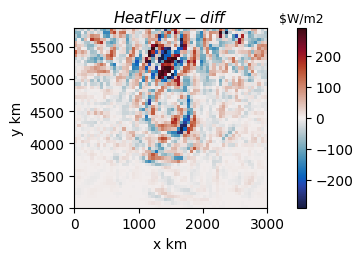

In [17]:
# High-resolution submesoscale heat flux
# ML_predicted submesoscale heat flux
# low-resolution submesoscale heat flux
# low resolution submesoscale heat flux with Fox Kemper parameterization

# path issue
import sys
from pathlib import Path
sys.path.insert(0, str(Path("/scratch/jczhang/submeso_data_driven").resolve()))

# check the velocity field and vorticity field
import numpy as np
import xarray as xr
from src.utils import read_mitgcm
from src.utils import build_coarse_grid
from src.utils import wT_total
from src.utils import wT
from src.utils import make_grid
from src.utils import coarsen_UVWTS
from src.utils import mld_avg
import importlib
importlib.reload(wT_total)
importlib.reload(wT)
from matplotlib.colors import TwoSlopeNorm
from matplotlib.colors import Normalize
import cmocean.cm as cmo
import h5netcdf

from MITgcmutils import mds
import matplotlib.pyplot as plt
# other parameters
path_scratch = '/scratch/jczhang/'
path_high = 'MITgcm_baroclinic_instability_old/MITgcm/verification/tutorial_reentrant_channel/run/'
path_low_FK = 'MITgcm_50km_FK/verification/tutorial_reentrant_channel/run/'
path_low = 'MITgcm_50km/verification/tutorial_reentrant_channel/run/'
# grid parameters
ds_fine = read_mitgcm.read_mitgrid_staggered(path_scratch + path_high)
ds_coarse = build_coarse_grid.build_coarse_grid_staggered(ds_fine,box_j=10, box_i=10)
grid = make_grid.make_grid_periodic_x(ds_coarse)
ds_50 = read_mitgcm.read_mitgrid_staggered(path_scratch + path_low)
# load the data
GM_diags_FK = mds.rdmds(path_scratch + path_low_FK + 'Diags/' +'GM_diags', 2488320)
GM_diags = mds.rdmds(path_scratch + path_low + 'Diags/' +'GM_diags', 2488320)
# kpphbl = xr.DataArray(diagMXL[1, :,:], dims = ("j","i"), name = "kpphbl")
psiX_FK = GM_diags_FK[0, ...]   # (k, j, i_g)  GM_PsiX
psiY_FK = GM_diags_FK[1, ...]   # (k, j_g, i)  GM_PsiY

psiX = GM_diags[0, ...]   # (k, j, i_g)  GM_PsiX
psiY = GM_diags[1, ...]   # (k, j_g, i)  GM_PsiY

# Wrap as DataArrays with correct dims/coords if you have them
psiX_FK = xr.DataArray(psiX_FK, dims=("k","j","i_g"))
psiY_FK = xr.DataArray(psiY_FK, dims=("k","j_g","i"))
PsiX = xr.DataArray(psiX, dims=("k","j","i_g"))
PsiY = xr.DataArray(psiY, dims=("k","j_g","i"))
# 
# 
dPsiY_dx_FK = (psiY_FK.roll(i=-1, roll_coords=False) - psiY_FK) / ds_50["DXG"]
dPsiX_dy_FK = (psiX_FK.shift(j=-1) - psiX_FK) / ds_50["DYG"]
dPsiY_dx = (PsiY.roll(i=-1, roll_coords=False) - PsiY) / ds_50["DXG"]
dPsiX_dy = (PsiX.shift(j=-1) - PsiX) / ds_50["DYG"]
# interp
grid = make_grid.make_grid_periodic_x(ds_50)
dPsiY_dx_c_FK = grid.interp(dPsiY_dx_FK, "Y", boundary="fill")
dPsiX_dy_c_FK = grid.interp(dPsiX_dy_FK, "X", boundary="periodic")
dPsiY_dx_c = grid.interp(dPsiY_dx, "Y", boundary="fill")
dPsiX_dy_c = grid.interp(dPsiX_dy, "X", boundary="periodic")
# 
Wstar_FK = (dPsiY_dx_c_FK - dPsiX_dy_c_FK)
Wstar = (dPsiY_dx_c - dPsiX_dy_c)
rho0, cp = 1035.0, 3994.0
#  temperature 
ds_T_FK = xr.open_dataset("./T_annual_low_FK.nc", engine="h5netcdf")
ds_T = xr.open_dataset("./T_annual_low.nc", engine="h5netcdf")
# 
w_annual_low_FK = xr.open_dataset("./W_annual_low_FK.nc", engine="h5netcdf")
w_annual_low_FK = grid.interp(w_annual_low_FK["W"], "Z", boundary="fill")
w_annual_low = xr.open_dataset("./W_annual_low.nc", engine="h5netcdf")
w_annual_low = grid.interp(w_annual_low["W"], "Z", boundary="fill")

# 
wT_annual_low_FK = rho0 * cp * (Wstar_FK ) * ds_T_FK["T"]
wT_annual_low = rho0 * cp * (Wstar) * ds_T["T"]
diff = wT_annual_low_FK - wT_annual_low



def sym_limits(Z, q = 0.995):
    v = np.nanquantile(np.abs(Z), q)
    return float(v)

def pos_limits(Z, q=0.995):
    v = np.nanquantile(Z, q)
    return float(v)

def range_limits(Z, q = 0.995):
    """Return (vmin, vmax) from lower/upper quantiles."""
    vmin = np.nanquantile(Z, 1 - q)   # e.g. 0.5% if q=0.995
    vmax = np.nanquantile(Z, q)       # e.g. 99.5%
    return float(vmin), float(vmax)

# plot 
XC = ds_50["XC"][60:116,:]
YC = ds_50["YC"][60:116,:]
k = 1
fields = {
    r"$HeatFlux-diff$":         {"Z": diff[k,60:116,:],  "units": r"$W/m2",  "kind": "signed", "cmap": cmo.balance, "XC": XC/1e3, "YC":YC/1e3},
 
}     


# Compute norms/limits per field
for key, meta in fields.items():   
    Z = meta["Z"]
    if meta["kind"] == "signed":
        q = sym_limits(Z)
        meta["norm"] = TwoSlopeNorm(vcenter=0.0, vmin=-q, vmax=+q)
    elif meta["kind"] == "positive":
        vmin, vmax = range_limits(Z)
        meta["norm"] = Normalize(vmin=vmin, vmax=vmax)
    elif meta["kind"] == "seq":
        meta["norm"] = Normalize(vmin=np.nanmin(Z), vmax=np.nanmax(Z))
    else:
        meta["norm"] = None
vmin, vmax = range_limits(wT_annual_low_FK[k,60:116,:], q=1)  # <-- your function
shared_norm = Normalize(vmin=vmin, vmax=vmax)

# Plot: 2×5
fig, axes = plt.subplots(1,1, figsize=(7, 2.5), constrained_layout=True)
# --- dynamic number of panels ---
n_fields = len(fields)
# if only one panel
if n_fields == 1:
    axes = np.array([axes])
axes = axes.ravel()

for ax, (title, meta) in zip(axes, fields.items()):
    Z = meta["Z"]
    cmap = meta["cmap"]
    norm = meta["norm"]
    # norm = shared_norm
    XX = meta["XC"]
    YY = meta["YC"]
    pc = ax.pcolormesh(XX[:, :], YY[:, :], Z[:, :], shading='auto', cmap=cmap, norm=norm)
    ax.set_aspect('equal', adjustable='box')
    ax.set_title(title, fontsize=11, pad=4)
    ax.set_xlabel('x km'); ax.set_ylabel('y km')
    cb = fig.colorbar(pc, ax=ax, pad=0.02)
    cb.ax.set_title(meta["units"], pad=4, fontsize=9)
fig.savefig("./heatflux_annual_diff.png")
plt.show()

# calculate the mixed layer averaged heat flux

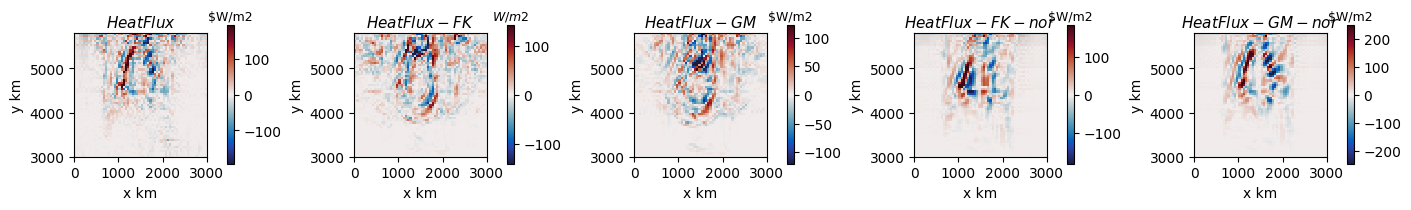

In [18]:
# High-resolution submesoscale heat flux
# ML_predicted submesoscale heat flux
# low-resolution submesoscale heat flux
# low resolution submesoscale heat flux with Fox Kemper parameterization

# path issue
import sys
from pathlib import Path
sys.path.insert(0, str(Path("/scratch/jczhang/submeso_data_driven").resolve()))

# check the velocity field and vorticity field
import numpy as np
import xarray as xr
from src.utils import read_mitgcm
from src.utils import build_coarse_grid
from src.utils import wT_total
from src.utils import wT
from src.utils import make_grid
from src.utils import coarsen_UVWTS
from src.utils import mld_avg
import importlib
importlib.reload(wT_total)
importlib.reload(wT)
from matplotlib.colors import TwoSlopeNorm
from matplotlib.colors import Normalize
import cmocean.cm as cmo
import h5netcdf
from src.utils import mld_avg

from MITgcmutils import mds
import matplotlib.pyplot as plt
# other parameters
path_scratch = '/scratch/jczhang/'
path_high = 'MITgcm_baroclinic_instability_old/MITgcm/verification/tutorial_reentrant_channel/run/'
path_low_FK = 'MITgcm_50km_FK/verification/tutorial_reentrant_channel/run/'
path_low = 'MITgcm_50km/verification/tutorial_reentrant_channel/run/'
# grid parameters
ds_fine = read_mitgcm.read_mitgrid_staggered(path_scratch + path_high)
ds_coarse = build_coarse_grid.build_coarse_grid_staggered(ds_fine,box_j=10, box_i=10)
grid = make_grid.make_grid_periodic_x(ds_coarse)
ds_50 = read_mitgcm.read_mitgrid_staggered(path_scratch + path_low)
# load the data
GM_diags_FK = mds.rdmds(path_scratch + path_low_FK + 'Diags/' +'GM_diags', 2488320)
GM_diags = mds.rdmds(path_scratch + path_low + 'Diags/' +'GM_diags', 2488320)
# kpphbl = xr.DataArray(diagMXL[1, :,:], dims = ("j","i"), name = "kpphbl")
psiX_FK = GM_diags_FK[0, ...]   # (k, j, i_g)  GM_PsiX
psiY_FK = GM_diags_FK[1, ...]   # (k, j_g, i)  GM_PsiY

psiX = GM_diags[0, ...]   # (k, j, i_g)  GM_PsiX
psiY = GM_diags[1, ...]   # (k, j_g, i)  GM_PsiY

# Wrap as DataArrays with correct dims/coords if you have them
psiX_FK = xr.DataArray(psiX_FK, dims=("k","j","i_g"))
psiY_FK = xr.DataArray(psiY_FK, dims=("k","j_g","i"))
PsiX = xr.DataArray(psiX, dims=("k","j","i_g"))
PsiY = xr.DataArray(psiY, dims=("k","j_g","i"))
# 
# 
dPsiY_dx_FK = (psiY_FK.roll(i=-1, roll_coords=False) - psiY_FK) / ds_50["DXG"]
dPsiX_dy_FK = (psiX_FK.shift(j=-1) - psiX_FK) / ds_50["DYG"]
dPsiY_dx = (PsiY.roll(i=-1, roll_coords=False) - PsiY) / ds_50["DXG"]
dPsiX_dy = (PsiX.shift(j=-1) - PsiX) / ds_50["DYG"]
# interp
grid = make_grid.make_grid_periodic_x(ds_50)
dPsiY_dx_c_FK = grid.interp(dPsiY_dx_FK, "Y", boundary="fill")
dPsiX_dy_c_FK = grid.interp(dPsiX_dy_FK, "X", boundary="periodic")
dPsiY_dx_c = grid.interp(dPsiY_dx, "Y", boundary="fill")
dPsiX_dy_c = grid.interp(dPsiX_dy, "X", boundary="periodic")
# 
Wstar_FK = (dPsiY_dx_c_FK - dPsiX_dy_c_FK)
Wstar = (dPsiY_dx_c - dPsiX_dy_c)
rho0, cp = 1035.0, 3994.0
#  temperature 
ds_T_FK = xr.open_dataset("./T_annual_low_FK.nc", engine="h5netcdf")
ds_T = xr.open_dataset("./T_annual_low.nc", engine="h5netcdf")
# 
w_annual_low_FK = xr.open_dataset("./W_annual_low_FK.nc", engine="h5netcdf")
w_annual_low_FK = grid.interp(w_annual_low_FK["W"], "Z", boundary="fill")
w_annual_low = xr.open_dataset("./W_annual_low.nc", engine="h5netcdf")
w_annual_low = grid.interp(w_annual_low["W"], "Z", boundary="fill")
# 
wT_annual_low_FK_nor = rho0 * cp * (w_annual_low_FK) * ds_T_FK["T"]
wT_annual_low_nor = rho0 * cp * (w_annual_low) * ds_T["T"]
# 
wT_annual_low_FK = rho0 * cp * (Wstar_FK ) * ds_T_FK["T"]
wT_annual_low = rho0 * cp * (Wstar) * ds_T["T"]
# 
ds_W_noGM = xr.open_dataset("./W_daily_low_noGM.nc", engine="h5netcdf")
W_noGM = grid.interp(ds_W_noGM["W"], "Z", to="center")  # (k,j,i)
ds_T_noGM = xr.open_dataset("./T_daily_low_noGM.nc", engine="h5netcdf")
wT_daily = ds_T_noGM["T"] * W_noGM
wT_annual_low_withoutGM = rho0 * cp * wT_daily.mean(dim="time")


kpphbl_FK = xr.open_dataset("../kpphbl_analysis/nc_file/kpphbl_annual_low_FK.nc", engine="h5netcdf")
kpphbl = xr.open_dataset("../kpphbl_analysis/nc_file/kpphbl_annual_low.nc", engine="h5netcdf")
wT_annual_low_FK = mld_avg.mld_avg(wT_annual_low_FK, kpphbl_FK["kpphbl"], ds_50)
wT_annual_low = mld_avg.mld_avg(wT_annual_low, kpphbl["kpphbl"], ds_50)

# c
wT_sub_mld = mld_avg.mld_avg(wT_sub_kC, kpphbl_coarse, ds_coarse)

def sym_limits(Z, q = 0.995):
    v = np.nanquantile(np.abs(Z), q)
    return float(v)

def pos_limits(Z, q=0.995):
    v = np.nanquantile(Z, q)
    return float(v)

def range_limits(Z, q = 0.995):
    """Return (vmin, vmax) from lower/upper quantiles."""
    vmin = np.nanquantile(Z, 1 - q)   # e.g. 0.5% if q=0.995
    vmax = np.nanquantile(Z, q)       # e.g. 99.5%
    return float(vmin), float(vmax)

# plot 
XC = ds_50["XC"][60:116,:]
YC = ds_50["YC"][60:116,:]
k = 12
fields = {
    r"$HeatFlux$":         {"Z": wT_annual_low_withoutGM[k,60:116,:],  "units": r"$W/m2",  "kind": "signed", "cmap": cmo.balance, "XC": XC/1e3, "YC":YC/1e3},
    r"$HeatFlux-FK$":         {"Z": wT_annual_low_FK[60:116,:],  "units": r"$W/m2$",  "kind": "signed", "cmap": cmo.balance, "XC": XC/1e3, "YC":YC/1e3},
    r"$HeatFlux-GM$":         {"Z": wT_annual_low[60:116,:],  "units": r"$W/m2",  "kind": "signed", "cmap": cmo.balance, "XC": XC/1e3, "YC":YC/1e3},
    r"$HeatFlux-FK-nor$":         {"Z": wT_annual_low_FK_nor[k,60:116,:],  "units": r"$W/m2",  "kind": "signed", "cmap": cmo.balance, "XC": XC/1e3, "YC":YC/1e3},
    r"$HeatFlux-GM-nor$":         {"Z": wT_annual_low_nor[k,60:116,:],  "units": r"$W/m2",  "kind": "signed", "cmap": cmo.balance, "XC": XC/1e3, "YC":YC/1e3},
}     


# Compute norms/limits per field
for key, meta in fields.items():   
    Z = meta["Z"]
    if meta["kind"] == "signed":
        q = sym_limits(Z)
        meta["norm"] = TwoSlopeNorm(vcenter=0.0, vmin=-q, vmax=+q)
    elif meta["kind"] == "positive":
        vmin, vmax = range_limits(Z)
        meta["norm"] = Normalize(vmin=vmin, vmax=vmax)
    elif meta["kind"] == "seq":
        meta["norm"] = Normalize(vmin=np.nanmin(Z), vmax=np.nanmax(Z))
    else:
        meta["norm"] = None
# vmin, vmax = range_limits(wT_annual_low_FK[k,60:116,:], q=1)  # <-- your function
# shared_norm = Normalize(vmin=vmin, vmax=vmax)

# Plot: 2×5
fig, axes = plt.subplots(1,5, figsize=(14, 2), constrained_layout=True)
# --- dynamic number of panels ---
n_fields = len(fields)
# if only one panel
if n_fields == 1:
    axes = np.array([axes])
axes = axes.ravel()

for ax, (title, meta) in zip(axes, fields.items()):
    Z = meta["Z"]
    cmap = meta["cmap"]
    norm = meta["norm"]
    # norm = shared_norm
    XX = meta["XC"]
    YY = meta["YC"]
    pc = ax.pcolormesh(XX[:, :], YY[:, :], Z[:, :], shading='auto', cmap=cmap, norm=norm)
    ax.set_aspect('equal', adjustable='box')
    ax.set_title(title, fontsize=11, pad=4)
    ax.set_xlabel('x km'); ax.set_ylabel('y km')
    cb = fig.colorbar(pc, ax=ax, pad=0.02)
    cb.ax.set_title(meta["units"], pad=4, fontsize=9)
fig.savefig("./heatflux_mixed_avg.png")
plt.show()

In [16]:
print(wT_annual_low_FK)

<xarray.Dataset> Size: 59kB
Dimensions:  (j: 120, i: 60)
Coordinates:
    k_p1     int64 8B 49
  * j        (j) int64 960B 0 1 2 3 4 5 6 7 ... 112 113 114 115 116 117 118 119
  * i        (i) int64 480B 0 1 2 3 4 5 6 7 8 9 ... 51 52 53 54 55 56 57 58 59
Data variables:
    kpphbl   (j, i) float64 58kB nan nan nan nan nan nan ... 0.0 0.0 0.0 0.0 0.0
